In [1]:
import os

import numpy as np
import pandas as pd

import nibabel as nib
from scipy.spatial.distance import euclidean

import bct
import networkx as nx
import igraph as ig
import leidenalg as la

import matplotlib.pyplot as plt

In [2]:
n = 360

label = ['VIS', 'SOM', 'DAN', 'VAN', 'LIM', 'FPN', 'DMN']
bound = [0, 28, 50, 74, 98, 117, 140, 180]

neworderlr = np.loadtxt('./inputs/neworderlr.txt')
neworder = np.array([np.where(neworderlr == i)[0][0] for i in range(len(neworderlr))])
oldorder = np.array([np.where(neworder == i)[0][0] for i in range(len(neworder))])

lrmerge = np.hstack([np.array([i, 180+i]) for i in range(180)])
lrsepar = np.hstack([np.array([i*2 for i in range(180)]), np.array([i*2+1 for i in range(180)])])

In [3]:
intra_mask = np.zeros((n, n))
for i in range(len(bound)-1): intra_mask[2*bound[i]:2*bound[i+1], 2*bound[i]:2*bound[i+1]] = 1
np.fill_diagonal(intra_mask, 0)

inter_mask = intra_mask.copy()
inter_mask = abs(inter_mask - 1)
np.fill_diagonal(inter_mask, 0)

In [4]:
iter = 10000

cr = 0; lr = 0
for _ in range(iter):
    g_rand = nx.gnm_random_graph(n, int(n*(n-1)/2*0.15))
    cr += nx.average_clustering(g_rand); lr += nx.average_shortest_path_length(g_rand)
cr /= iter; lr /= iter

In [5]:
atlas_gii_surf_L = nib.load('./inputs/S1200.L.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf_R = nib.load('./inputs/S1200.R.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf = np.vstack([atlas_gii_surf_L, atlas_gii_surf_R])
atlas_gii_label_L = nib.load('./inputs/L.Glasser2016.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R = nib.load('./inputs/R.Glasser2016.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R[atlas_gii_label_R != 0] += 1000
atlas_gii_label = np.hstack([atlas_gii_label_L, atlas_gii_label_R])
roi_labels = np.unique(atlas_gii_label); roi_labels = sorted(roi_labels[roi_labels != 0])
centroids = [np.mean(atlas_gii_surf[np.argwhere(atlas_gii_label == label).flatten()], axis = 0) for label in roi_labels]

distance = np.zeros((len(roi_labels), len(roi_labels)))
distance = np.array([[euclidean(centroids[i], centroids[j]) for j in range(len(roi_labels))] for i in range(len(roi_labels))])

In [6]:
def flat_without_diagonal(matrix):

    matrix = matrix.copy()
    n = matrix.shape[0]
    upper = matrix[np.triu_indices(n, k =  1)]
    lower = matrix[np.tril_indices(n, k = -1)]
    
    return np.concatenate([upper, lower])

In [7]:
def binarize(W, percentile, zero_diagonal = True, directed = True):
    
    W = W.copy(); W = abs(W)
    if zero_diagonal: np.fill_diagonal(W, 0)
    if directed == False: W = np.array([[max(W[i, j], W[j, i]) for j in range(W.shape[1])] for i in range(W.shape[0])])
    
    if zero_diagonal: thre = np.percentile(flat_without_diagonal(W), percentile)
    else: thre = np.percentile(W, percentile)
    
    W[W < thre] = 0; W[W > 0] = 1

    return W

In [8]:
def network_effi(binary_matrix):

    binary_matrix = binary_matrix.copy()[neworder].T[neworder].T[lrmerge].T[lrmerge].T
    dist = bct.distance_bin(binary_matrix)
    res = np.zeros((len(label), len(label)))
    for i in range(len(label)):
        for j in range(len(label)):
            if i == j: res[i, j] = np.mean(1/flat_without_diagonal(dist[2*bound[i]:2*bound[i+1], 2*bound[j]:2*bound[j+1]]))
            else: res[i, j] = np.mean(1/dist[2*bound[i]:2*bound[i+1], 2*bound[j]:2*bound[j+1]])
    
    intra_effi = np.mean(1/(dist[intra_mask == 1]))
    inter_effi = np.mean(1/(dist[inter_mask == 1]))

    return res, intra_effi, inter_effi

In [9]:
def network_cost(binary_matrix):

    binary_matrix = binary_matrix.copy()[neworder].T[neworder].T[lrmerge].T[lrmerge].T
    dist = distance.copy()[neworder].T[neworder].T[lrmerge].T[lrmerge].T
    res = np.zeros((len(label), len(label)))
    for i in range(len(label)):
        for j in range(len(label)):
            res[i, j] = np.sum((binary_matrix*dist)[2*bound[i]:2*bound[i+1], 2*bound[j]:2*bound[j+1]]) / np.sum(dist[2*bound[i]:2*bound[i+1], 2*bound[j]:2*bound[j+1]])

    intra_cost = np.sum(binary_matrix*dist*intra_mask) / np.sum(dist*intra_mask)
    inter_cost = np.sum(binary_matrix*dist*inter_mask) / np.sum(dist*inter_mask)

    return res, intra_cost, inter_cost

#### compute graph theory metrics

In [10]:
os.makedirs('./outputs', exist_ok = True)

In [11]:
res_data = {
    'FILE_ID': [], 'lambda': [], 
    'global_cost': [], 'global_effi': [], 
    'VIS2VIS_cost': [], 'SOM2VIS_cost': [], 'DAN2VIS_cost': [], 'VAN2VIS_cost': [], 'LIM2VIS_cost': [], 'FPN2VIS_cost': [], 'DMN2VIS_cost': [], 
    'VIS2SOM_cost': [], 'SOM2SOM_cost': [], 'DAN2SOM_cost': [], 'VAN2SOM_cost': [], 'LIM2SOM_cost': [], 'FPN2SOM_cost': [], 'DMN2SOM_cost': [], 
    'VIS2DAN_cost': [], 'SOM2DAN_cost': [], 'DAN2DAN_cost': [], 'VAN2DAN_cost': [], 'LIM2DAN_cost': [], 'FPN2DAN_cost': [], 'DMN2DAN_cost': [], 
    'VIS2VAN_cost': [], 'SOM2VAN_cost': [], 'DAN2VAN_cost': [], 'VAN2VAN_cost': [], 'LIM2VAN_cost': [], 'FPN2VAN_cost': [], 'DMN2VAN_cost': [], 
    'VIS2LIM_cost': [], 'SOM2LIM_cost': [], 'DAN2LIM_cost': [], 'VAN2LIM_cost': [], 'LIM2LIM_cost': [], 'FPN2LIM_cost': [], 'DMN2LIM_cost': [], 
    'VIS2FPN_cost': [], 'SOM2FPN_cost': [], 'DAN2FPN_cost': [], 'VAN2FPN_cost': [], 'LIM2FPN_cost': [], 'FPN2FPN_cost': [], 'DMN2FPN_cost': [], 
    'VIS2DMN_cost': [], 'SOM2DMN_cost': [], 'DAN2DMN_cost': [], 'VAN2DMN_cost': [], 'LIM2DMN_cost': [], 'FPN2DMN_cost': [], 'DMN2DMN_cost': [], 
    'VIS2VIS_effi': [], 'SOM2VIS_effi': [], 'DAN2VIS_effi': [], 'VAN2VIS_effi': [], 'LIM2VIS_effi': [], 'FPN2VIS_effi': [], 'DMN2VIS_effi': [], 
    'VIS2SOM_effi': [], 'SOM2SOM_effi': [], 'DAN2SOM_effi': [], 'VAN2SOM_effi': [], 'LIM2SOM_effi': [], 'FPN2SOM_effi': [], 'DMN2SOM_effi': [], 
    'VIS2DAN_effi': [], 'SOM2DAN_effi': [], 'DAN2DAN_effi': [], 'VAN2DAN_effi': [], 'LIM2DAN_effi': [], 'FPN2DAN_effi': [], 'DMN2DAN_effi': [], 
    'VIS2VAN_effi': [], 'SOM2VAN_effi': [], 'DAN2VAN_effi': [], 'VAN2VAN_effi': [], 'LIM2VAN_effi': [], 'FPN2VAN_effi': [], 'DMN2VAN_effi': [], 
    'VIS2LIM_effi': [], 'SOM2LIM_effi': [], 'DAN2LIM_effi': [], 'VAN2LIM_effi': [], 'LIM2LIM_effi': [], 'FPN2LIM_effi': [], 'DMN2LIM_effi': [], 
    'VIS2FPN_effi': [], 'SOM2FPN_effi': [], 'DAN2FPN_effi': [], 'VAN2FPN_effi': [], 'LIM2FPN_effi': [], 'FPN2FPN_effi': [], 'DMN2FPN_effi': [], 
    'VIS2DMN_effi': [], 'SOM2DMN_effi': [], 'DAN2DMN_effi': [], 'VAN2DMN_effi': [], 'LIM2DMN_effi': [], 'FPN2DMN_effi': [], 'DMN2DMN_effi': [], 
    'target_edge_attack_05_effi': [], 'target_edge_attack_10_effi': [], 'target_edge_attack_15_effi': [], 'target_edge_attack_20_effi': [], 
    'target_edge_attack_25_effi': [], 'target_edge_attack_30_effi': [], 'target_edge_attack_35_effi': [], 'target_edge_attack_40_effi': [], 
    'target_edge_attack_45_effi': [], 'target_edge_attack_50_effi': [], 'target_edge_attack_55_effi': [], 'target_edge_attack_60_effi': [], 
    'target_edge_attack_65_effi': [], 'target_edge_attack_70_effi': [], 'target_edge_attack_75_effi': [], 'target_edge_attack_80_effi': [], 
    'target_edge_attack_85_effi': [], 'target_edge_attack_90_effi': [], 'target_edge_attack_95_effi': [], 
    'clustering_coefficient': [], 'characteristic_path_length': [], 'normalized_clustering_coefficient': [], 'normalized_characteristic_path_length': [], 'small_worldness': [], 
    'local_effi': [], 'modularity': [], 'module_number': [], 
    'intra_effi': [], 'inter_effi': [], 'intra_cost': [], 'inter_cost': [], 
}

In [12]:
sub = '118730'

lambdas = np.linspace(0.02, 0.98, 49)

for lam in lambdas:

    res_data['FILE_ID'].append(sub); res_data['lambda'].append(lam)
    raw_W = np.load('./inputs/matrices/{}_{:02d}.npz'.format(sub, round(lam*100)))['arr_0']
    bin_W = binarize(raw_W, 85, zero_diagonal = True, directed = True)

    res_data['global_cost'].append(np.sum(bin_W * distance) / np.sum(distance))
    res_data['global_effi'].append(bct.efficiency_bin(bin_W))
    
    nl_cost, intra_cost, inter_cost = network_cost(bin_W)
    for i in range(len(label)):
        for j in range(len(label)):
            res_data['{}2{}_cost'.format(label[j], label[i])].append(nl_cost[i, j])
    res_data['intra_cost'].append(intra_cost)
    res_data['inter_cost'].append(inter_cost)

    nl_effi, intra_effi, inter_effi = network_effi(bin_W)
    for i in range(len(label)):
        for j in range(len(label)):
            res_data['{}2{}_effi'.format(label[j], label[i])].append(nl_effi[i, j])
    res_data['intra_effi'].append(intra_effi)
    res_data['inter_effi'].append(inter_effi)
    
    G = nx.from_numpy_array(bin_W.T, create_using = nx.DiGraph)
    bc_dict = nx.edge_betweenness_centrality(G, normalized = False)
    bc_matr = bin_W.copy().T.astype(float); bc_matr[bc_matr == 1] = np.array(list(bc_dict.values())); bc_matr = bc_matr.T
    attacks = np.linspace(0.05, 0.95, 19)
    for att in attacks:
        thre = np.percentile(bc_matr[bc_matr > 0], 100-round(att*100))
        reserved_edges = (bc_matr < thre).astype(int) - (bc_matr == 0).astype(int)
        res_data['target_edge_attack_{:02d}_effi'.format(round(att*100))].append(bct.efficiency_bin(reserved_edges))
    
    res_data['local_effi'].append(np.mean(bct.efficiency_bin(bin_W, local = True)))

    graph = nx.from_numpy_array(bin_W[neworder].T[neworder].T[lrmerge].T[lrmerge], create_using = nx.DiGraph)
    wccs = list(nx.weakly_connected_components(graph))
    outside_wcc = [list(comp)[0] for comp in wccs if len(comp) == 1]
    graph = ig.Graph.TupleList(graph.edges(), directed = True)
    partition = la.find_partition(graph, la.ModularityVertexPartition)
    res_data['modularity'].append(partition.quality()); res_data['module_number'].append(len(set(partition.membership)))

    bin_W = binarize(raw_W, 85, zero_diagonal = True, directed = False)
    graph = nx.from_numpy_array(bin_W)
    c = nx.average_clustering(graph)
    if nx.is_connected(graph): l = nx.average_shortest_path_length(graph)
    else: l = float('inf')
    res_data['clustering_coefficient'].append(c); res_data['characteristic_path_length'].append(l)
    res_data['normalized_clustering_coefficient'].append(c/cr); res_data['normalized_characteristic_path_length'].append(l/lr)
    res_data['small_worldness'].append((c/cr)/(l/lr))

df = pd.DataFrame(res_data); df.to_csv('./outputs/graphical_res_HCP_MMP(distance_ridge).csv', index = False)

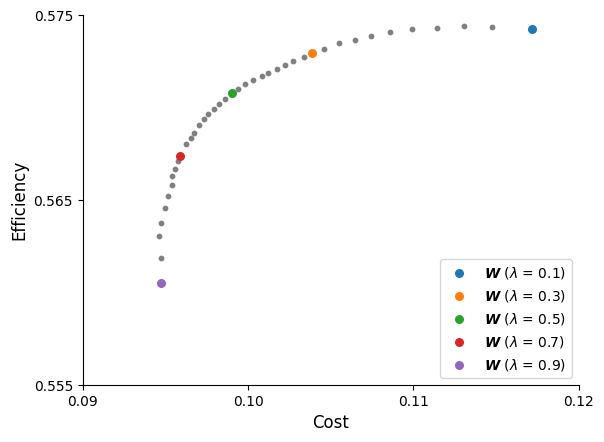

In [13]:
filtered_df = df[(df['lambda'] > 0.1 -1e-3) & (df['lambda'] < 0.9 + 1e-3)]

plt.scatter(filtered_df['global_cost'], filtered_df['global_effi'], color = 'grey', zorder = 1, s = 10)

for i in range(5):
    l = 0.2 * i + 0.1
    plt.scatter(
        filtered_df[abs(filtered_df['lambda'] - l) < 1e-3]['global_cost'], 
        filtered_df[abs(filtered_df['lambda'] - l) < 1e-3]['global_effi'], 
        color = plt.get_cmap('tab10').colors[i], zorder = 2, s = 30, 
        label = r'$\boldsymbol{W}$ '+r'($\lambda$ = {:.1f})'.format(l)
    )

ax = plt.gca(); ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel('Cost', fontsize = 12); plt.xlim(0.09, 0.12); plt.xticks([0.09, 0.10, 0.11, 0.12], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.555, 0.575); plt.yticks([0.555, 0.565, 0.575], fontsize = 10)
plt.legend(loc = 'lower right', fontsize = 10)

plt.show()